# BCSE331L - Exploratory Data Analysis
## Retail banking customer profiles: preparation, visualization, clustering and models
This notebook is designed for Google Colab. Use **Runtime -> Run all** to run the complete project in sequence. Review the generated tables and figures, then write your own short interpretation in the conclusion before submission.

---

## Project summary

This project applies the BCSE331L syllabus topics in Modules 2-7 to the supplied CSV. The filename contains “credit card”, but the columns describe **5,000 retail-bank customer records**, including income, credit-card ownership and personal-loan acceptance. The project therefore describes the data by its observed schema. It does not claim that the records are credit-card transactions, defaults, or a time series.

The project includes the syllabus methods that can be applied to these records. Where the CSV has no required input (dates, natural-language documents, or action/reward sequences), a clearly labeled synthetic teaching example is used to demonstrate the method separately.

**Data source:** [salemprakash/EDA - credit card.csv](https://raw.githubusercontent.com/salemprakash/EDA/main/Data/credit%20card.csv)

### Questions

1. What are the distributions, quality issues and relationships in the customer profile variables?
2. Can unsupervised methods describe customer segments, and how do their assumptions differ?
3. How well can a simple model predict income or historical personal-loan acceptance in a held-out sample?

### Module map

| Syllabus module | Notebook coverage |
|---|---|
| 2 - Data Transformation | duplicates, replacing invalid values, binning, missing-data methods, maximum-likelihood estimation |
| 3 - Correlation Analysis and Time Series | univariate/bivariate/multivariate analysis; separate synthetic date-indexing, grouping and resampling exercise |
| 4 - Data Summarization and Visualization | statistical summaries, contingency tables, n-dimensional summaries, scatter, dot and bar charts |
| 5 - Clustering Algorithms | k-means, spectral, Gaussian mixture/EM, agglomerative hierarchy, MST, document-vector clustering and DBSCAN outliers |
| 6 - Dimensionality Reduction | PCA, SVD, factor analysis, intrinsic-dimension estimate, non-metric MDS, Isomap and a small self-organizing map |
| 7 - Model Development and Evaluation | linear regression, classification accuracy and limits, supervised-learning versus reinforcement-learning demonstration |


## 1. Environment and reproducibility

The following cells use common packages available in Google Colab. The fixed random seed makes sampling and model demonstrations repeatable. The notebook fetches the CSV directly; if that is unavailable, the next cell offers a local upload fallback.


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans, SpectralClustering
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.manifold import Isomap, MDS
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, mean_absolute_error, mean_squared_error,
                             r2_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neighbors import kneighbors_graph
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
print("Core packages imported. Random seed:", RANDOM_STATE)


Core packages imported. Random seed: 42


## 2. Load and inspect the dataset

Inspect the shape, column names, data types and sample rows before analysis. The source file uses `?` as a missing-value marker in some records. `ID` and `ZIP_Code` are identifiers/location codes; they are not treated as measurements in customer-segmentation or prediction features.


In [ ]:
DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/credit%20card.csv"

try:
    raw = pd.read_csv(DATA_URL, na_values=["?", "NA", ""])
    print("Loaded dataset from the supplied public URL.")
except Exception as error:
    print("Could not fetch the URL:", error)
    print("Upload the supplied CSV file to continue.")
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("No CSV file was uploaded.")
    raw = pd.read_csv(csv_files[0], na_values=["?", "NA", ""])

raw.columns = raw.columns.astype(str).str.strip().str.replace(r"\s+", "_", regex=True)
print("Shape:", raw.shape)
display(raw.head())
display(raw.dtypes.rename("data_type").to_frame())
print("Duplicate full rows:", int(raw.duplicated().sum()))
if "ID" in raw.columns:
    print("Unique IDs:", raw["ID"].nunique(), "of", len(raw))
display(raw.describe(include="all").T)


Loaded dataset from the supplied public URL.
Shape: (5000, 14)


,ID,Age,Experience,Income,ZIP_Code,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.600,1,0,0.000,1.000,0.000,0,0.000
1,2,45,19,34,90089,3,1.500,1,0,0.000,1.000,0.000,0,0.000
2,3,39,15,11,94720,1,1.000,1,0,0.000,0.000,0.000,0,0.000
3,4,35,9,100,94112,1,2.700,2,0,0.000,0.000,0.000,0,0.000
4,5,35,8,45,91330,4,1.000,2,0,0.000,0.000,0.000,0,1.000


,data_type
ID,int64
Age,int64
Experience,int64
Income,int64
ZIP_Code,int64
Family,int64
CCAvg,float64
Education,int64
Mortgage,int64
Personal_Loan,float64


Duplicate full rows: 0
Unique IDs: 5000 of 5000


,count,mean,std,min,25%,50%,75%,max
ID,"5,000.000","2,500.500","1,443.520",1.000,"1,250.750","2,500.500","3,750.250","5,000.000"
Age,"5,000.000",45.338,11.463,23.000,35.000,45.000,55.000,67.000
Experience,"5,000.000",20.105,11.468,-3.000,10.000,20.000,30.000,43.000
Income,"5,000.000",73.774,46.034,8.000,39.000,64.000,98.000,224.000
ZIP_Code,"5,000.000","93,152.503","2,121.852","9,307.000","91,911.000","93,437.000","94,608.000","96,651.000"
Family,"5,000.000",2.396,1.148,1.000,1.000,2.000,3.000,4.000
CCAvg,"5,000.000",1.938,1.748,0.000,0.700,1.500,2.500,10.000
Education,"5,000.000",1.881,0.840,1.000,1.000,2.000,3.000,3.000
Mortgage,"5,000.000",56.499,101.714,0.000,0.000,0.000,101.000,635.000
Personal_Loan,"4,989.000",0.096,0.295,0.000,0.000,0.000,0.000,1.000


### Working data dictionary

The CSV has no accompanying dictionary or unit definitions. Labels below are interpreted from column names; values remain in their original coding unless a cell explicitly creates a display label. Treat numeric education codes as category levels rather than measured distances. The units of `Income`, `CCAvg` and `Mortgage` are not specified in this CSV.

| Field | Working interpretation | Handling |
|---|---|---|
| `ID` | Record identifier | Excluded from models and clustering |
| `Age`, `Experience`, `Income`, `Family`, `CCAvg`, `Mortgage` | Numeric customer profile measures | Summarized; negative `Experience` treated as invalid |
| `ZIP_Code` | Postal code | Excluded from models and clustering |
| `Education` | Coded education category | Kept as code; interpreted categorically |
| `Personal_Loan`, `Securities_Account`, `CD_Account`, `Online`, `CreditCard` | Yes/no indicators | Analyzed as binary-coded values |

These are historical sample associations. They do not establish causes or provide a basis for lending decisions.


## Module 2 - Data transformation
### 2.1 Deduplication, replacement and validity checks

The cleaning rules are explicit and reported: remove duplicate rows, convert leftover question marks to missing values, and mark negative work-experience values as invalid. We preserve the raw frame and create a separate cleaned frame.


In [ ]:
data = raw.copy().replace(r"^\s*\?\s*$", np.nan, regex=True)
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

duplicate_rows = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
negative_experience = int((data["Experience"] < 0).sum()) if "Experience" in data else 0
if "Experience" in data:
    data.loc[data["Experience"] < 0, "Experience"] = np.nan

print(f"Removed duplicate rows: {duplicate_rows}")
print(f"Negative Experience values replaced with missing: {negative_experience}")
print("Cleaned shape:", data.shape)


Removed duplicate rows: 0
Negative Experience values replaced with missing: 52
Cleaned shape: (5000, 14)


### 2.2 Missingness and traditional handling methods

Measure missingness before filling values. Traditional methods include dropping incomplete rows, mean/median imputation for numeric data, and mode imputation for categories. We compare these choices, then use median imputation for the numeric analysis copy because income-like measures can be skewed. Model evaluation later fits its imputer on training data only.


,missing_count,missing_percent
Experience,52,1.040
Personal_Loan,11,0.220
CD_Account,2,0.040
Securities_Account,1,0.020
CreditCard,1,0.020


Rows with at least one missing value: 66


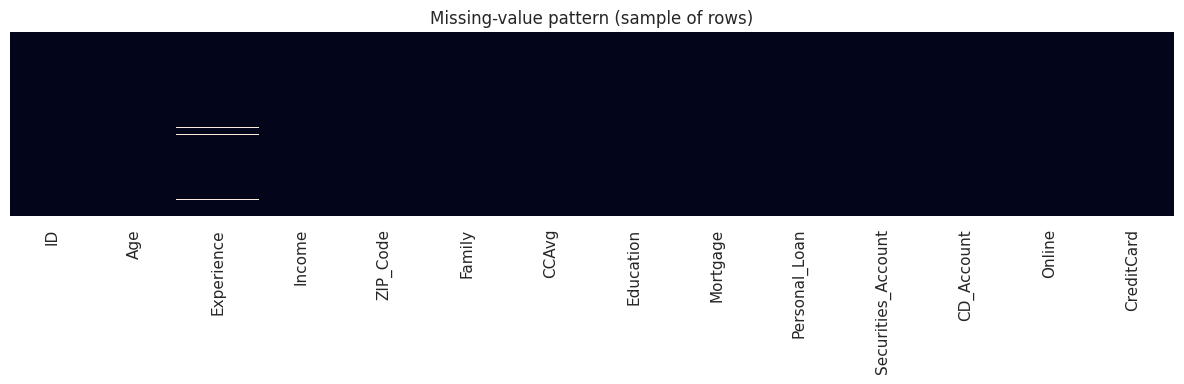


Income example: available 5000 of 5000
Complete-case row count: 4934
Mean replacement: 73.774 | median replacement: 64.0
Remaining missing values in analysis copy: 0


In [ ]:
missing_count = data.isna().sum().sort_values(ascending=False)
missing_rate = (data.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.DataFrame({"missing_count": missing_count, "missing_percent": missing_rate})
display(missing_table[missing_table["missing_count"] > 0])
print("Rows with at least one missing value:", int(data.isna().any(axis=1).sum()))
if data.isna().any().any():
    plt.figure(figsize=(12, 4))
    missing_sample = data.sample(min(400, len(data)), random_state=RANDOM_STATE)
    sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False)
    plt.title("Missing-value pattern (sample of rows)")
    plt.tight_layout()
    plt.show()
income = data["Income"].dropna()
print("\nIncome example: available", len(income), "of", len(data))
print("Complete-case row count:", len(data.dropna()))
print("Mean replacement:", round(income.mean(), 3), "| median replacement:", round(income.median(), 3))

analysis = data.copy()
for column in analysis.columns:
    if analysis[column].isna().any():
        if pd.api.types.is_numeric_dtype(analysis[column]):
            analysis[column] = analysis[column].fillna(analysis[column].median())
        else:
            modes = analysis[column].mode(dropna=True)
            if not modes.empty:
                analysis[column] = analysis[column].fillna(modes.iloc[0])
print("Remaining missing values in analysis copy:", int(analysis.isna().sum().sum()))


### 2.3 Replacing values and discretization/binning

For presentation, binary fields and education codes can be replaced with labels without changing the original numeric analysis data. Binning compresses a continuous scale into ranges and loses detail, so keep the original columns for statistical models.


In [ ]:
education_labels = {1: "Level 1", 2: "Level 2", 3: "Level 3"}
binary_labels = {0: "No", 1: "Yes"}
display_labels = analysis[["Education", "Personal_Loan", "CreditCard"]].copy()
display_labels["Education_label"] = display_labels["Education"].map(education_labels)
display_labels["Personal_Loan_label"] = display_labels["Personal_Loan"].map(binary_labels)
display_labels["CreditCard_label"] = display_labels["CreditCard"].map(binary_labels)
display(display_labels.head())

analysis["Age_band"] = pd.cut(analysis["Age"], [0, 29, 44, 59, np.inf],
                              labels=["Under 30", "30-44", "45-59", "60+"], include_lowest=True)
analysis["Income_quartile"] = pd.qcut(analysis["Income"].rank(method="first"), q=4,
                                      labels=["Q1", "Q2", "Q3", "Q4"])
display(analysis[["Age", "Age_band", "Income", "Income_quartile"]].head(10))


,Education,Personal_Loan,CreditCard,Education_label,Personal_Loan_label,CreditCard_label
0,1,0.000,0.000,Level 1,No,No
1,1,0.000,0.000,Level 1,No,No
2,1,0.000,0.000,Level 1,No,No
3,2,0.000,0.000,Level 2,No,No
4,2,0.000,1.000,Level 2,No,Yes


,Age,Age_band,Income,Income_quartile
0,25,Under 30,49,Q2
1,45,45-59,34,Q1
2,39,30-44,11,Q1
3,35,30-44,100,Q4
4,35,30-44,45,Q2
5,37,30-44,29,Q1
6,53,45-59,72,Q3
7,50,45-59,22,Q1
8,35,30-44,81,Q3
9,34,30-44,180,Q4


### 2.4 Maximum-likelihood estimation (MLE)

For a normal model, the maximum-likelihood estimates are the sample mean and the population-form variance (divide by *n*). This cell fits a normal curve to `Income` to demonstrate estimation. Income may be skewed, so the overlay is a teaching example rather than a claim that income is normally distributed.


Normal-model MLE mean (mu): 73.774
Normal-model MLE standard deviation (sigma): 46.029


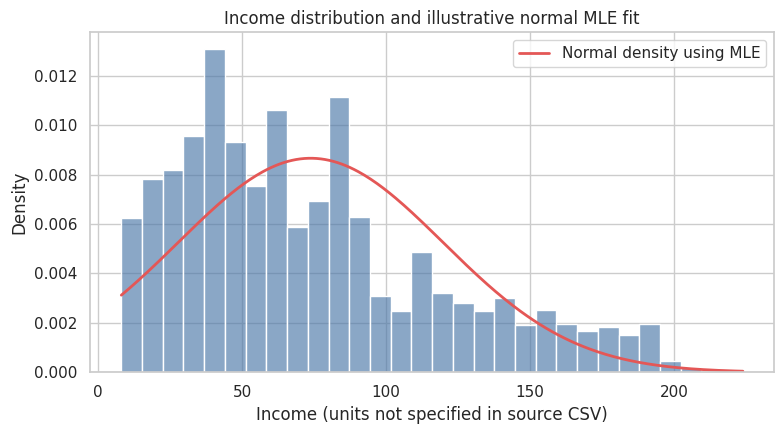

In [ ]:
income_values = analysis["Income"].to_numpy(dtype=float)
mle_mu, mle_sigma = stats.norm.fit(income_values)
print(f"Normal-model MLE mean (mu): {mle_mu:.3f}")
print(f"Normal-model MLE standard deviation (sigma): {mle_sigma:.3f}")
x_grid = np.linspace(income_values.min(), income_values.max(), 300)
plt.figure(figsize=(8, 4.5))
sns.histplot(income_values, bins=30, stat="density", color="#4C78A8", alpha=0.65)
plt.plot(x_grid, stats.norm.pdf(x_grid, loc=mle_mu, scale=mle_sigma), color="#E45756", lw=2,
         label="Normal density using MLE")
plt.title("Income distribution and illustrative normal MLE fit")
plt.xlabel("Income (units not specified in source CSV)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


## Module 3 - Correlation analysis and time series
### 3.1 Univariate, bivariate and multivariate analysis

Univariate analysis describes one variable; bivariate analysis compares two; multivariate analysis considers several together. These summaries are descriptive. Correlation does not imply causation.


,count,mean,std,min,25%,50%,75%,max
Age,"5,000.000",45.338,11.463,23.000,35.000,45.000,55.000,67.000
Experience,"5,000.000",20.328,11.253,0.000,11.000,20.000,30.000,43.000
Income,"5,000.000",73.774,46.034,8.000,39.000,64.000,98.000,224.000
Family,"5,000.000",2.396,1.148,1.000,1.000,2.000,3.000,4.000
CCAvg,"5,000.000",1.938,1.748,0.000,0.700,1.500,2.500,10.000
Mortgage,"5,000.000",56.499,101.714,0.000,0.000,0.000,101.000,635.000


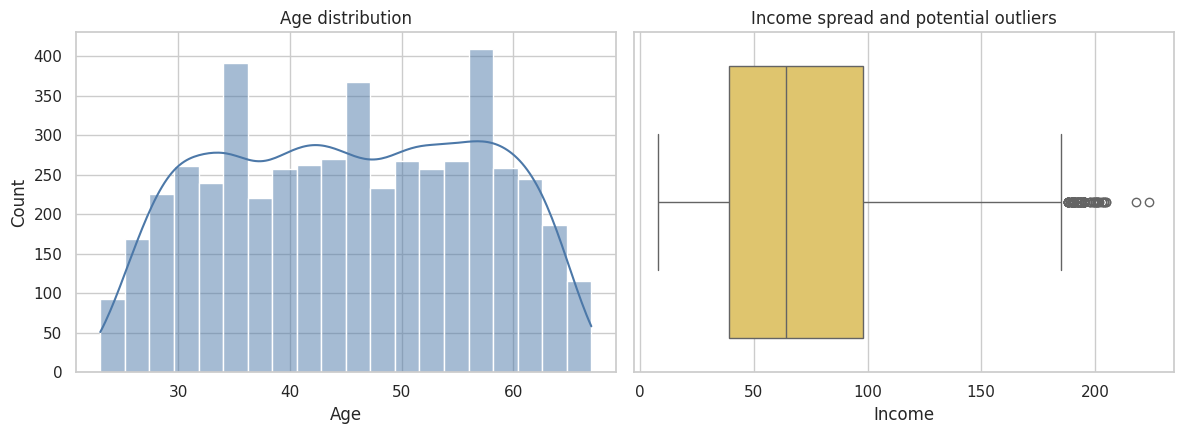

Pearson correlation: Income and CCAvg = 0.646


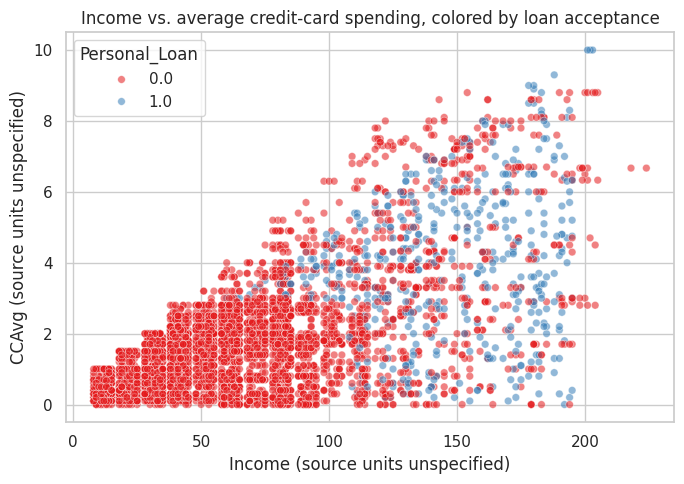

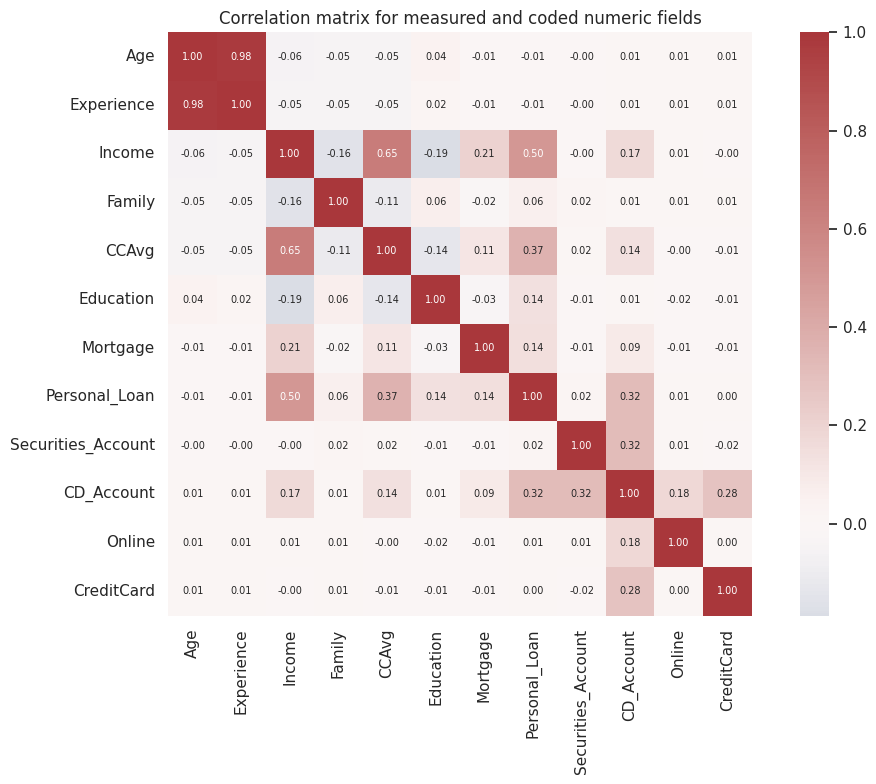

In [ ]:
display(analysis[["Age", "Experience", "Income", "Family", "CCAvg", "Mortgage"]].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(analysis["Age"], bins=20, kde=True, ax=axes[0], color="#4C78A8")
axes[0].set_title("Age distribution")
sns.boxplot(x=analysis["Income"], ax=axes[1], color="#F2CF5B")
axes[1].set_title("Income spread and potential outliers")
plt.tight_layout()
plt.show()
print("Pearson correlation: Income and CCAvg =", round(analysis["Income"].corr(analysis["CCAvg"]), 3))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=analysis, x="Income", y="CCAvg", hue="Personal_Loan",
                alpha=0.55, palette="Set1", s=30)
plt.title("Income vs. average credit-card spending, colored by loan acceptance")
plt.xlabel("Income (source units unspecified)")
plt.ylabel("CCAvg (source units unspecified)")
plt.tight_layout()
plt.show()

numeric_features = ["Age", "Experience", "Income", "Family", "CCAvg", "Education",
                    "Mortgage", "Personal_Loan", "Securities_Account", "CD_Account", "Online", "CreditCard"]
corr = analysis[numeric_features].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True, annot_kws={"size": 7})
plt.title("Correlation matrix for measured and coded numeric fields")
plt.tight_layout()
plt.show()


### 3.2 Time-based indexing, grouping and resampling

The customer CSV has no date or event-time column, so it cannot support a real customer time-series analysis. The following **synthetic monthly series** demonstrates a date-time index, grouping by branch, visualization, rolling means and quarterly resampling. Do not mix it with customer-level findings.


,Branch,Accounts_opened
Date,,
2024-01-01,North,16
2024-01-01,South,15
2024-02-01,North,15
2024-02-01,South,19
2024-03-01,North,21


Branch  Date      
North   2024-01-01    52
        2024-04-01    54
        2024-07-01    46
        2024-10-01    49
        2025-01-01    69
        2025-04-01    69
        2025-07-01    62
        2025-10-01    60
Name: Accounts_opened, dtype: int64

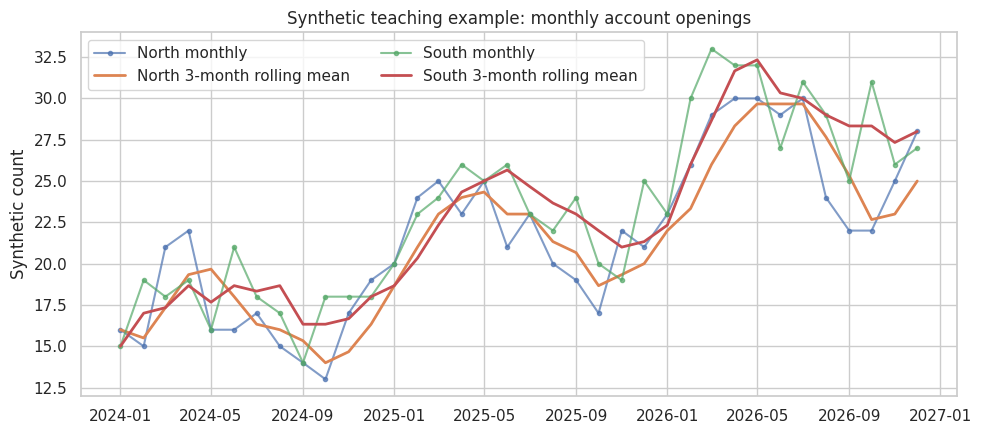

Branch  Date      
North   2024-01-01    52
        2024-04-01    54
        2024-07-01    46
        2024-10-01    49
        2025-01-01    69
        2025-04-01    69
        2025-07-01    62
        2025-10-01    60
Name: quarterly_total, dtype: int64

In [ ]:
dates = pd.date_range("2024-01-01", periods=36, freq="MS")
synthetic_rows = []
for branch_index, branch in enumerate(["North", "South"]):
    local_rng = np.random.default_rng(RANDOM_STATE + branch_index)
    trend = np.linspace(15, 28 + branch_index * 4, len(dates))
    season = 4 * np.sin(np.arange(len(dates)) * 2 * np.pi / 12)
    noise = local_rng.normal(0, 2, len(dates))
    for date, value in zip(dates, trend + season + noise):
        synthetic_rows.append({"Date": date, "Branch": branch,
                               "Accounts_opened": max(0, round(value))})
monthly_demo = pd.DataFrame(synthetic_rows).set_index("Date").sort_index()
display(monthly_demo.head())
display(monthly_demo.groupby("Branch").resample("QS")["Accounts_opened"].sum().head(8))

fig, ax = plt.subplots(figsize=(10, 4.5))
for branch, group in monthly_demo.groupby("Branch"):
    series = group["Accounts_opened"].asfreq("MS")
    ax.plot(series.index, series, marker="o", ms=3, alpha=0.7, label=f"{branch} monthly")
    ax.plot(series.index, series.rolling(3, min_periods=1).mean(), lw=2,
            label=f"{branch} 3-month rolling mean")
ax.set_title("Synthetic teaching example: monthly account openings")
ax.set_ylabel("Synthetic count")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()
quarterly_demo = monthly_demo.groupby("Branch").resample("QS")["Accounts_opened"].sum()
display(quarterly_demo.rename("quarterly_total").head(8))


## Module 4 - Data summarization and visualization
### 4.1 One-dimensional, two-dimensional and n-dimensional summaries

The cells report one-dimensional summaries, two-way contingency tables and a three-way grouping. Percentages help compare groups of different sizes.


In [ ]:
one_d = analysis[["Income", "Age", "CCAvg", "Mortgage"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T
one_d["skew"] = analysis[["Income", "Age", "CCAvg", "Mortgage"]].skew()
one_d["kurtosis"] = analysis[["Income", "Age", "CCAvg", "Mortgage"]].kurtosis()
display(one_d)

loan_by_education = pd.crosstab(analysis["Education"], analysis["Personal_Loan"],
                                rownames=["Education code"], colnames=["Personal Loan accepted"], margins=True)
display(loan_by_education)
display(pd.crosstab(analysis["Education"], analysis["Personal_Loan"], normalize="index")
        .rename(columns={0: "No", 1: "Yes"}))
n_d_summary = (analysis.groupby(["Age_band", "Education", "Personal_Loan"], observed=True)["Income"]
               .agg(["count", "median", "mean"]).reset_index())
display(n_d_summary.head(16))


,count,mean,median,std,min,max,skew,kurtosis
Income,"5,000.000",73.774,64.000,46.034,8.000,224.000,0.841,-0.044
Age,"5,000.000",45.338,45.000,11.463,23.000,67.000,-0.029,-1.153
CCAvg,"5,000.000",1.938,1.500,1.748,0.000,10.000,1.598,2.647
Mortgage,"5,000.000",56.499,0.000,101.714,0.000,635.000,2.104,4.757


Personal Loan accepted,0.000,1.000,All
Education code,,,
1,2003,93,2096
2,1221,182,1403
3,1296,205,1501
All,4520,480,5000


Personal_Loan,No,Yes
Education,,
1,0.956,0.044
2,0.870,0.130
3,0.863,0.137


,Age_band,Education,Personal_Loan,count,median,mean
0,Under 30,1,0.000,200,92.000,95.820
1,Under 30,1,1.000,9,135.000,131.333
2,Under 30,2,0.000,122,44.000,48.689
3,Under 30,2,1.000,22,132.000,140.227
4,Under 30,3,0.000,117,49.000,56.308
5,Under 30,3,1.000,18,151.000,149.722
6,30-44,1,0.000,783,75.000,85.580
7,30-44,1,1.000,38,140.000,139.026
8,30-44,2,0.000,450,48.000,52.240
9,30-44,2,1.000,68,141.000,144.706


### 4.2 Scatter, bar and dot visualizations

The dot chart shows group-level personal-loan acceptance rates and the bar chart shows counts by education code. Each visual answers a different question; none should be read without considering group size and the data limitations.


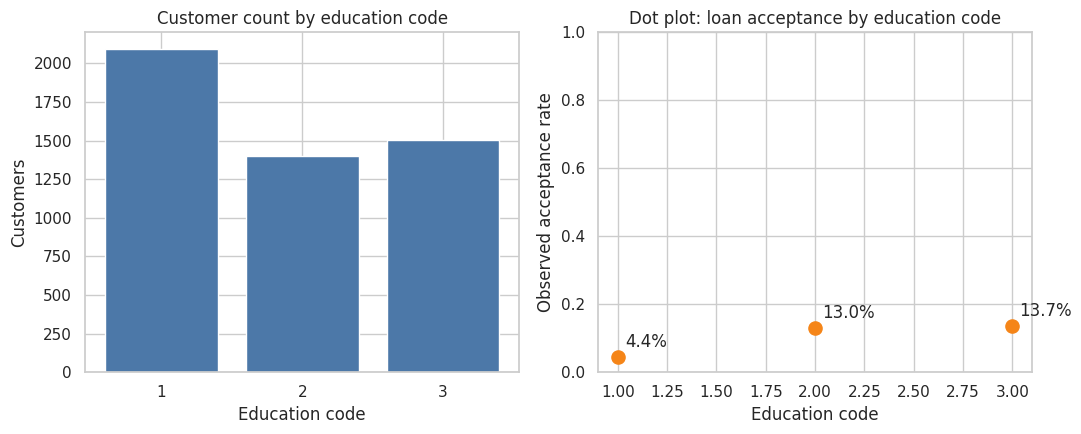

In [ ]:
education_rate = analysis.groupby("Education")["Personal_Loan"].mean()
education_count = analysis.groupby("Education")["Personal_Loan"].size()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(education_count.index.astype(str), education_count.values, color="#4C78A8")
axes[0].set(title="Customer count by education code", xlabel="Education code", ylabel="Customers")
axes[1].scatter(education_rate.index, education_rate.values, s=90, color="#F58518")
axes[1].set(title="Dot plot: loan acceptance by education code", xlabel="Education code",
            ylabel="Observed acceptance rate", ylim=(0, 1))
for x, y in education_rate.items():
    axes[1].annotate(f"{y:.1%}", (x, y), xytext=(5, 7), textcoords="offset points")
plt.tight_layout()
plt.show()


## Module 5 - Clustering algorithms

Clustering is unsupervised: it does not use `Personal_Loan` to form segments. The feature set excludes `ID`, `ZIP_Code` and the loan outcome. The loan outcome may be used after clustering to describe groups, but not to create them. Standardization matters because features have different scales.


In [ ]:
cluster_columns = ["Age", "Experience", "Income", "Family", "CCAvg", "Education", "Mortgage"]
X_cluster_raw = analysis[cluster_columns].to_numpy(dtype=float)
X_cluster = StandardScaler().fit_transform(X_cluster_raw)
cluster_rng = np.random.default_rng(RANDOM_STATE)
print("Clustering matrix:", X_cluster.shape)


Clustering matrix: (5000, 7)


### 5.1 K-means baseline and segment profiles

K-means assigns each record to its nearest centroid and favors compact groups. Compare inertia and silhouette over several candidate values of *k*. The silhouette score is a separation diagnostic, not proof that real-world customer types exist.


,k,inertia,silhouette
0,2,"8,176.700",0.204
1,3,"6,693.146",0.226
2,4,"5,991.869",0.238
3,5,"5,509.918",0.197
4,6,"4,975.305",0.196


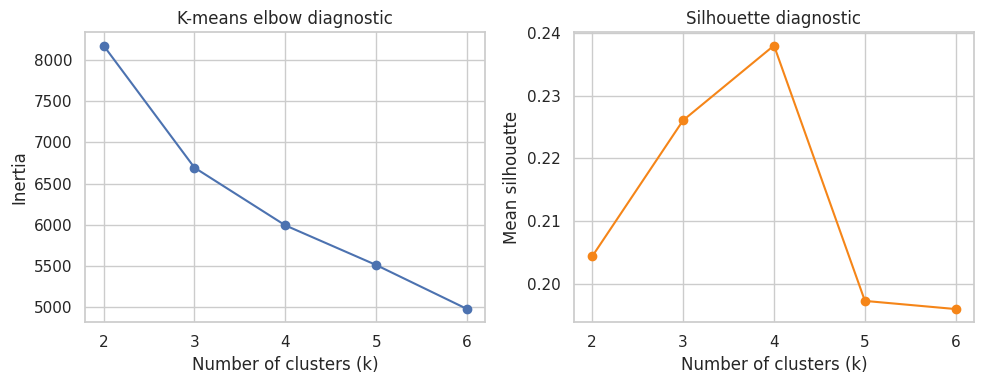

,customer_count,median_age,median_income,median_ccavg,loan_acceptance_rate
KMeans_cluster,,,,,
0,425,44.000,113.000,2.670,0.294
1,1914,35.000,53.000,1.200,0.033
2,678,44.000,142.000,4.700,0.335
3,1983,56.000,50.000,1.300,0.033


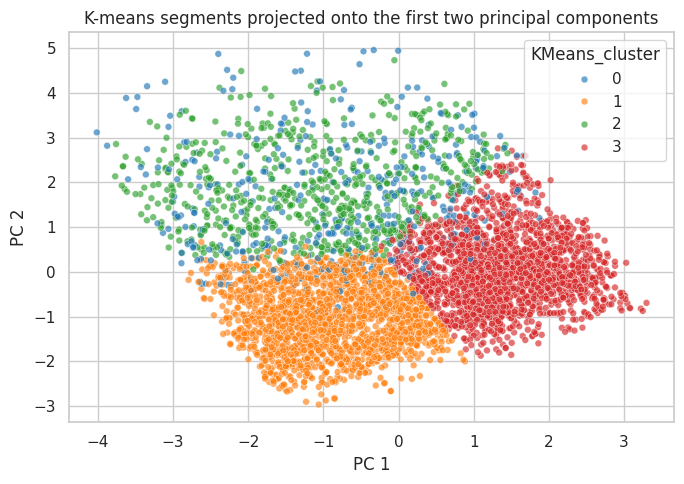

In [ ]:
sample_n = min(1500, len(X_cluster))
cluster_indices = cluster_rng.choice(len(X_cluster), size=sample_n, replace=False)
X_cluster_sample = X_cluster[cluster_indices]
k_results = []
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = candidate.fit_predict(X_cluster_sample)
    k_results.append({"k": k, "inertia": candidate.inertia_,
                      "silhouette": silhouette_score(X_cluster_sample, labels,
                                                     sample_size=min(1000, sample_n), random_state=RANDOM_STATE)})
k_table = pd.DataFrame(k_results)
display(k_table)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o")
axes[0].set(title="K-means elbow diagnostic", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#F58518")
axes[1].set(title="Silhouette diagnostic", xlabel="Number of clusters (k)", ylabel="Mean silhouette")
plt.tight_layout()
plt.show()

n_segments = 4
kmeans_model = KMeans(n_clusters=n_segments, n_init=10, random_state=RANDOM_STATE)
analysis["KMeans_cluster"] = kmeans_model.fit_predict(X_cluster)
segment_profile = analysis.groupby("KMeans_cluster").agg(
    customer_count=("ID", "size"), median_age=("Age", "median"),
    median_income=("Income", "median"), median_ccavg=("CCAvg", "median"),
    loan_acceptance_rate=("Personal_Loan", "mean"))
display(segment_profile)
viz_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_cluster)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=viz_pca[:, 0], y=viz_pca[:, 1], hue=analysis["KMeans_cluster"],
                palette="tab10", s=24, alpha=0.65)
plt.title("K-means segments projected onto the first two principal components")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()


### 5.2 Spectral clustering

Spectral clustering builds a neighborhood graph and clusters an embedding of that graph. It can capture non-spherical structure but is more expensive, so this demonstration uses at most 1,000 customers.


In [ ]:
spectral_n = min(1000, len(X_cluster))
spectral_idx = cluster_rng.choice(len(X_cluster), size=spectral_n, replace=False)
X_spectral = X_cluster[spectral_idx]
spectral = SpectralClustering(n_clusters=n_segments, affinity="nearest_neighbors", n_neighbors=15,
                              assign_labels="kmeans", random_state=RANDOM_STATE)
spectral_labels = spectral.fit_predict(X_spectral)
display(pd.Series(spectral_labels).value_counts().sort_index().rename("customers").to_frame())
print("Silhouette on sample:", round(silhouette_score(X_spectral, spectral_labels), 3))


,customers
0,211
1,272
2,165
3,352


Silhouette on sample: 0.168


### 5.3 Model-based clustering with Gaussian mixtures and EM

A Gaussian mixture models the feature distribution as a weighted sum of Gaussian components. The expectation-maximization (EM) algorithm alternates between estimating soft memberships and updating component parameters. `predict_proba` gives these membership probabilities; AIC/BIC help compare model sizes subject to assumptions.


In [ ]:
gmm_rows = min(1500, len(X_cluster))
gmm_idx = cluster_rng.choice(len(X_cluster), size=gmm_rows, replace=False)
X_gmm = X_cluster[gmm_idx]
gmm_candidates = []
for k in range(2, 7):
    candidate = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE).fit(X_gmm)
    gmm_candidates.append({"components": k, "AIC": candidate.aic(X_gmm), "BIC": candidate.bic(X_gmm)})
display(pd.DataFrame(gmm_candidates))
gmm_model = GaussianMixture(n_components=n_segments, covariance_type="full",
                            random_state=RANDOM_STATE).fit(X_gmm)
gmm_probabilities = gmm_model.predict_proba(X_gmm)
print("EM converged:", gmm_model.converged_, "| iterations:", gmm_model.n_iter_)
display(pd.DataFrame(gmm_probabilities[:5], columns=[f"component_{i}" for i in range(n_segments)]))


,components,AIC,BIC
0,2,"21,639.965","22,017.204"
1,3,"9,094.294","9,662.809"
2,4,"8,385.132","9,144.922"
3,5,"7,685.129","8,636.195"
4,6,"5,917.670","7,060.013"


EM converged: True | iterations: 39


,component_0,component_1,component_2,component_3
0,0.000,0.000,0.597,0.403
1,0.000,0.000,0.000,1.000
2,0.000,1.000,0.000,0.000
3,0.000,1.000,0.000,0.000
4,0.000,1.000,0.000,0.000


### 5.4 Agglomerative hierarchy and minimum spanning tree

Agglomerative clustering repeatedly merges the closest groups. Ward linkage limits the increase in within-cluster variance; the dendrogram is truncated because a full 5,000-leaf plot is unreadable. An MST connects observations using the shortest collection of edges. Removing unusually long MST edges gives a simple clustering demonstration; the 95th-percentile cutoff is a teaching heuristic, not a universal optimum.


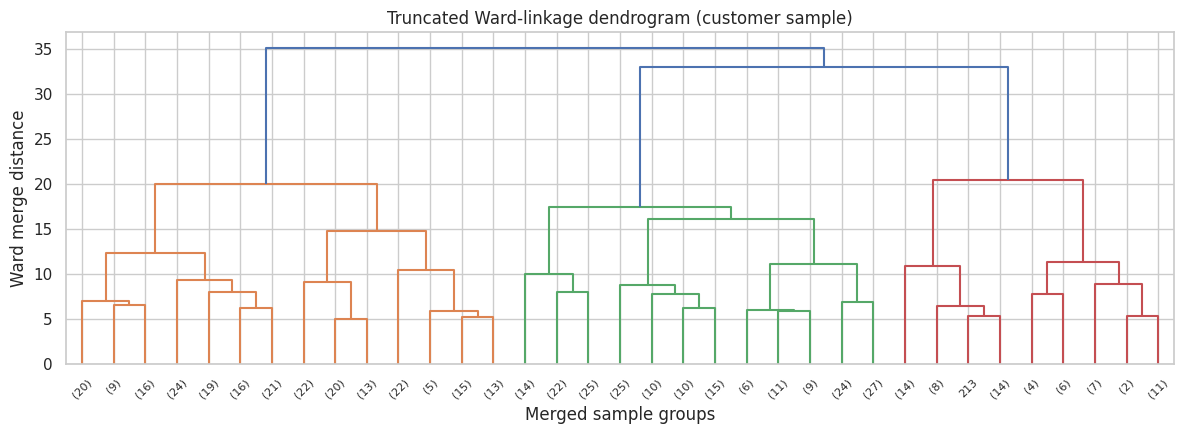

,customers
0,235
1,30
2,198
3,37


MST edges: 499 | 95th-percentile cutoff: 1.591
Components after removing long edges: 26


,customers
0,466
1,4
2,3
6,2
9,2
14,2
19,2
4,1
5,1
3,1


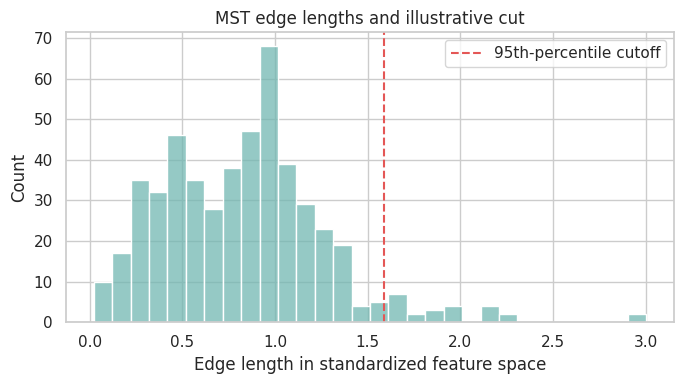

In [ ]:
hier_n = min(500, len(X_cluster))
hier_idx = cluster_rng.choice(len(X_cluster), size=hier_n, replace=False)
X_hier = X_cluster[hier_idx]
Z = linkage(X_hier, method="ward", metric="euclidean")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=35, show_leaf_counts=True)
plt.title("Truncated Ward-linkage dendrogram (customer sample)")
plt.xlabel("Merged sample groups")
plt.ylabel("Ward merge distance")
plt.tight_layout()
plt.show()
agg = AgglomerativeClustering(n_clusters=n_segments, linkage="ward")
agg_labels = agg.fit_predict(X_hier)
display(pd.Series(agg_labels).value_counts().sort_index().rename("customers").to_frame())

knn_graph = kneighbors_graph(X_hier, n_neighbors=10, mode="distance", include_self=False)
undirected_graph = knn_graph.maximum(knn_graph.T)
tree = minimum_spanning_tree(undirected_graph).tocsr()
edge_lengths = tree.data.copy()
edge_cutoff = float(np.quantile(edge_lengths, 0.95))
trimmed_tree = tree.copy()
trimmed_tree.data[trimmed_tree.data > edge_cutoff] = 0
trimmed_tree.eliminate_zeros()
component_count, mst_labels = connected_components(trimmed_tree + trimmed_tree.T,
                                                    directed=False, return_labels=True)
print(f"MST edges: {len(edge_lengths)} | 95th-percentile cutoff: {edge_cutoff:.3f}")
print("Components after removing long edges:", component_count)
display(pd.Series(mst_labels).value_counts().head(10).rename("customers").to_frame())
plt.figure(figsize=(7, 4))
sns.histplot(edge_lengths, bins=30, color="#72B7B2")
plt.axvline(edge_cutoff, color="#E45756", linestyle="--", label="95th-percentile cutoff")
plt.title("MST edge lengths and illustrative cut")
plt.xlabel("Edge length in standardized feature space")
plt.legend()
plt.tight_layout()
plt.show()


### 5.5 Document clustering demonstration

This CSV has no natural-language text. To demonstrate a document-clustering workflow without inventing source text, the next cell turns structured records into **synthetic profile sentences** from binned fields, converts these to TF-IDF vectors and clusters them. This is a method demonstration, not a claim that written customer descriptions exist in the dataset.


In [ ]:
doc_sample = analysis.sample(min(2500, len(analysis)), random_state=RANDOM_STATE).copy()
doc_sample["Age_band"] = pd.cut(doc_sample["Age"], [0, 29, 44, 59, np.inf],
                                labels=["young", "midcareer", "mature", "senior"], include_lowest=True)
doc_sample["Income_band"] = pd.qcut(doc_sample["Income"].rank(method="first"), 4,
                                    labels=["income_low", "income_lower_mid", "income_upper_mid", "income_high"])
doc_sample["Spend_band"] = pd.cut(doc_sample["CCAvg"], [-np.inf, 1, 3, np.inf],
                                  labels=["spend_low", "spend_medium", "spend_high"])
documents = [
    f"{age} {income} {spend} family_{family} education_{education} online_{online}"
    for age, income, spend, family, education, online in zip(
        doc_sample["Age_band"].astype(str), doc_sample["Income_band"].astype(str),
        doc_sample["Spend_band"].astype(str), doc_sample["Family"].astype(int),
        doc_sample["Education"].astype(int), doc_sample["Online"].astype(int))
]
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
document_matrix = tfidf.fit_transform(documents)
document_model = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
doc_sample["Document_cluster"] = document_model.fit_predict(document_matrix)
display(doc_sample.groupby("Document_cluster").agg(
    records=("ID", "size"), median_income=("Income", "median"),
    loan_acceptance_rate=("Personal_Loan", "mean")))
print("Example generated profile:", documents[0])


,records,median_income,loan_acceptance_rate
Document_cluster,,,
0,625,24.000,0.000
1,627,140.000,0.381
2,623,50.000,0.000
3,625,81.000,0.027


Example generated profile: midcareer income_low spend_low family_2 education_2 online_0


### 5.6 Outlier detection using density clustering

DBSCAN marks points in sparse regions as noise (`-1`) and can find clusters without specifying their number. Results depend on distance scale and the `eps`/`min_samples` choices. “Noise” does not mean fraud, error or an undesirable customer.


In [ ]:
db_n = min(1500, len(X_cluster))
db_idx = cluster_rng.choice(len(X_cluster), size=db_n, replace=False)
X_db = X_cluster[db_idx]
db_labels = DBSCAN(eps=2.5, min_samples=12).fit_predict(X_db)
noise_share = float(np.mean(db_labels == -1))
print(f"DBSCAN noise share at the chosen settings: {noise_share:.1%}")
display(pd.Series(db_labels).value_counts().sort_index().rename("sample_count").to_frame())


DBSCAN noise share at the chosen settings: 0.2%


,sample_count
-1,3
0,1497


## Module 6 - Dimensionality reduction
### 6.1 PCA, SVD and intrinsic dimension

PCA rotates centered, scaled measurements into orthogonal directions ordered by explained variance. SVD is the matrix factorization used to derive principal directions. The cumulative-variance curve estimates how many components retain a chosen share of variance; it is not a universal definition of intrinsic dimension.


Components needed to retain at least 90% of variance: 5


,component,variance_ratio,cumulative_variance
0,1,0.290,0.290
1,2,0.255,0.545
2,3,0.141,0.687
3,4,0.133,0.819
4,5,0.129,0.948
5,6,0.049,0.997
6,7,0.003,1.000


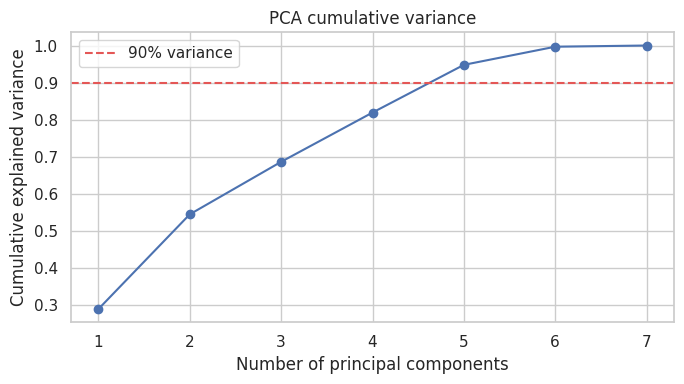

First five SVD variance ratios: [0.2898 0.2553 0.1415 0.1327 0.1285]
Compare with PCA ratios: [0.2898 0.2553 0.1415 0.1327 0.1285]


In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_cluster)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print("Components needed to retain at least 90% of variance:", n_for_90)
display(pd.DataFrame({"component": np.arange(1, len(explained) + 1),
                      "variance_ratio": explained, "cumulative_variance": cumulative}))
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.90, color="#E45756", linestyle="--", label="90% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative variance")
plt.xticks(np.arange(1, len(cumulative) + 1))
plt.legend()
plt.tight_layout()
plt.show()

U, singular_values, VT = np.linalg.svd(X_cluster, full_matrices=False)
svd_variance_ratio = singular_values**2 / np.sum(singular_values**2)
print("First five SVD variance ratios:", np.round(svd_variance_ratio[:5], 4))
print("Compare with PCA ratios:", np.round(explained[:5], 4))


### 6.2 Factor analysis

Factor analysis models observed variables as combinations of fewer latent factors plus variable-specific noise. Factor signs and ordering are not uniquely determined. Interpret loadings as an exploratory summary, not as discovered causes.


In [ ]:
factor_model = FactorAnalysis(n_components=3, random_state=RANDOM_STATE)
factor_model.fit(X_cluster)
factor_loadings = pd.DataFrame(factor_model.components_.T, index=cluster_columns,
                               columns=["Factor_1", "Factor_2", "Factor_3"])
display(factor_loadings.round(3))


,Factor_1,Factor_2,Factor_3
Age,0.989,0.001,-0.004
Experience,0.988,0.008,0.005
Income,-0.057,0.868,0.155
Family,-0.046,-0.169,-0.073
CCAvg,-0.054,0.788,-0.267
Education,0.031,-0.200,-0.089
Mortgage,-0.014,0.201,0.176


### 6.3 Nonlinear MDS and manifold learning

Non-metric multidimensional scaling (MDS) tries to preserve the rank ordering of pairwise dissimilarities in a low-dimensional map. Isomap approximates geodesic distances over a neighborhood graph. Both are sensitive to samples and parameters, so these examples use a reproducible subset.


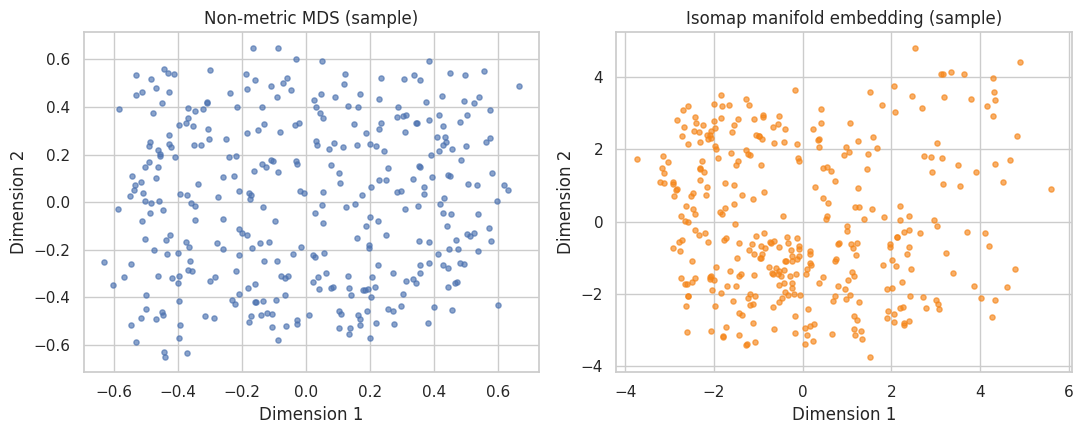

In [ ]:
manifold_n = min(350, len(X_cluster))
manifold_idx = cluster_rng.choice(len(X_cluster), size=manifold_n, replace=False)
X_manifold = X_cluster[manifold_idx]
nonmetric_mds = MDS(n_components=2, metric=False, n_init=1, max_iter=100,
                    random_state=RANDOM_STATE, dissimilarity="euclidean")
mds_embedding = nonmetric_mds.fit_transform(X_manifold)
isomap_embedding = Isomap(n_neighbors=10, n_components=2).fit_transform(X_manifold)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(mds_embedding[:, 0], mds_embedding[:, 1], s=14, alpha=0.65)
axes[0].set_title("Non-metric MDS (sample)")
axes[1].scatter(isomap_embedding[:, 0], isomap_embedding[:, 1], s=14, alpha=0.65, color="#F58518")
axes[1].set_title("Isomap manifold embedding (sample)")
for ax in axes:
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
plt.tight_layout()
plt.show()


### 6.4 Self-organizing map (SOM)

A SOM is a competitive neural map that places similar observations near one another on a low-dimensional grid. This compact NumPy implementation trains a 6 by 6 map on a sample to illustrate the algorithm.


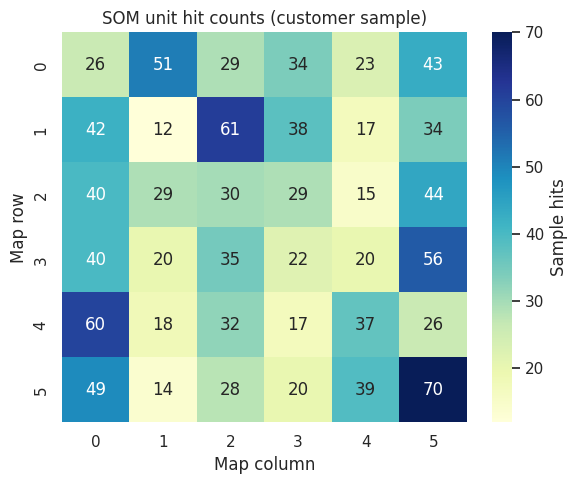

In [ ]:
som_n = min(1200, len(X_cluster))
som_idx = cluster_rng.choice(len(X_cluster), size=som_n, replace=False)
X_som = X_cluster[som_idx]
grid_size = 6
som_rng = np.random.default_rng(RANDOM_STATE)
weights = som_rng.normal(0, 0.5, size=(grid_size, grid_size, X_som.shape[1]))
grid_y, grid_x = np.indices((grid_size, grid_size))
steps = 1800
for step in range(steps):
    sample = X_som[som_rng.integers(0, len(X_som))]
    distances = np.sum((weights - sample) ** 2, axis=2)
    best_y, best_x = np.unravel_index(np.argmin(distances), distances.shape)
    progress = step / steps
    learning_rate = 0.35 * (1 - progress) + 0.02
    radius = max(0.6, (grid_size / 2) * (1 - progress))
    grid_distance = (grid_y - best_y) ** 2 + (grid_x - best_x) ** 2
    neighborhood = np.exp(-grid_distance / (2 * radius**2))
    weights += learning_rate * neighborhood[:, :, None] * (sample - weights)

hits = np.zeros((grid_size, grid_size), dtype=int)
for sample in X_som:
    winner = np.unravel_index(np.argmin(np.sum((weights - sample) ** 2, axis=2)),
                              (grid_size, grid_size))
    hits[winner] += 1
plt.figure(figsize=(6, 5))
sns.heatmap(hits, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Sample hits"})
plt.title("SOM unit hit counts (customer sample)")
plt.xlabel("Map column")
plt.ylabel("Map row")
plt.tight_layout()
plt.show()


## Module 7 - Model development and evaluation
### 7.1 Linear regression for a continuous outcome

Linear regression uses `Income` as a continuous target. The train/test split happens before imputation so held-out data do not influence preprocessing. For a continuous target, report MAE, RMSE and R-squared; classification accuracy is not an appropriate regression metric.


,test_set
MAE,26.281
RMSE,33.593
R_squared,0.468


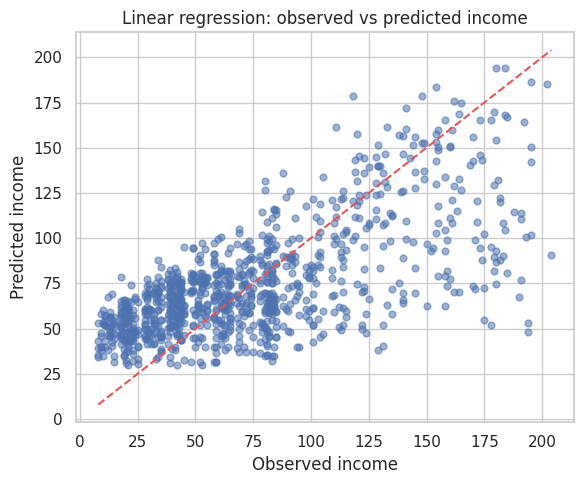

In [ ]:
regression_features = ["Age", "Experience", "Family", "CCAvg", "Education", "Mortgage",
                       "Securities_Account", "CD_Account", "Online", "CreditCard"]
X_reg = data[regression_features]
y_reg = data["Income"]
reg_valid = y_reg.notna()
X_train, X_test, y_train, y_test = train_test_split(
    X_reg.loc[reg_valid], y_reg.loc[reg_valid], test_size=0.2, random_state=RANDOM_STATE)
linear_model = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
linear_model.fit(X_train, y_train)
income_pred = linear_model.predict(X_test)
regression_metrics = pd.Series({
    "MAE": mean_absolute_error(y_test, income_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, income_pred)),
    "R_squared": r2_score(y_test, income_pred),
}, name="test_set")
display(regression_metrics.to_frame())
plt.figure(figsize=(6, 5))
plt.scatter(y_test, income_pred, alpha=0.55, s=24)
lower, upper = min(y_test.min(), income_pred.min()), max(y_test.max(), income_pred.max())
plt.plot([lower, upper], [lower, upper], color="#E45756", linestyle="--")
plt.xlabel("Observed income")
plt.ylabel("Predicted income")
plt.title("Linear regression: observed vs predicted income")
plt.tight_layout()
plt.show()


### 7.2 Classification accuracy and evaluation limits

The binary target `Personal_Loan` supports classification. The logistic-regression example reports accuracy, balanced accuracy, a confusion matrix and per-class precision/recall. A majority-class baseline shows why accuracy alone can mislead when classes are imbalanced. These are sample predictions, not approval recommendations.


In [ ]:
classification_features = ["Age", "Experience", "Income", "Family", "CCAvg", "Education", "Mortgage",
                            "Securities_Account", "CD_Account", "Online", "CreditCard"]
X_cls = data[classification_features]
y_cls = data["Personal_Loan"].astype("Int64")
cls_valid = y_cls.notna()
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls.loc[cls_valid], y_cls.loc[cls_valid].astype(int), test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_cls.loc[cls_valid].astype(int))
classifier = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                           LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
classifier.fit(X_train_c, y_train_c)
loan_pred = classifier.predict(X_test_c)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_c, y_train_c)
baseline_pred = baseline.predict(X_test_c)
print(f"Logistic-regression accuracy: {accuracy_score(y_test_c, loan_pred):.3f}")
print(f"Majority-class baseline accuracy: {accuracy_score(y_test_c, baseline_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_c, loan_pred):.3f}")
print("\nClassification report:\n", classification_report(y_test_c, loan_pred, zero_division=0))
print("Confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(confusion_matrix(y_test_c, loan_pred),
                     index=["Actual No", "Actual Yes"], columns=["Predicted No", "Predicted Yes"]))


Logistic-regression accuracy: 0.946
Majority-class baseline accuracy: 0.904
Balanced accuracy: 0.812

Classification report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       902
           1       0.76      0.65      0.70        96

    accuracy                           0.95       998
   macro avg       0.86      0.81      0.83       998
weighted avg       0.94      0.95      0.94       998

Confusion matrix (rows=true, columns=predicted):


,Predicted No,Predicted Yes
Actual No,882,20
Actual Yes,34,62


### 7.3 Supervised and reinforcement learning

**Supervised learning** learns from examples with known labels or targets; the loan-acceptance classifier uses a known target. **Reinforcement learning (RL)** learns by taking actions in an environment and receiving rewards or penalties. This CSV has no action/reward sequence, so RL cannot be trained from it. The small grid world below is a separate synthetic Q-learning example, illustrating an application pattern such as route planning.


In [ ]:
# Synthetic 4x4 grid world: start at 0, goal at 15, obstacles at 5 and 9.
grid_n, goal_state, obstacles = 4, 15, {5, 9}
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
q_table = np.zeros((grid_n * grid_n, len(actions)))
rl_rng = np.random.default_rng(RANDOM_STATE)
alpha, gamma = 0.2, 0.95

def move(state, action_index):
    row, col = divmod(state, grid_n)
    dr, dc = actions[action_index]
    next_row, next_col = int(np.clip(row + dr, 0, grid_n - 1)), int(np.clip(col + dc, 0, grid_n - 1))
    next_state = next_row * grid_n + next_col
    if next_state in obstacles:
        next_state = state
    reward = 10 if next_state == goal_state else -1
    return next_state, reward, next_state == goal_state

for episode in range(600):
    state = 0
    epsilon = max(0.03, 0.8 * (1 - episode / 600))
    for _ in range(60):
        action = int(rl_rng.integers(len(actions))) if rl_rng.random() < epsilon else int(np.argmax(q_table[state]))
        next_state, reward, done = move(state, action)
        target = reward if done else reward + gamma * np.max(q_table[next_state])
        q_table[state, action] += alpha * (target - q_table[state, action])
        state = next_state
        if done:
            break
state = 0
greedy_path = [state]
for _ in range(20):
    if state == goal_state:
        break
    state, _, _ = move(state, int(np.argmax(q_table[state])))
    greedy_path.append(state)
print("Learned greedy path as flattened grid states:", greedy_path)
print("Reached goal:", greedy_path[-1] == goal_state)


Learned greedy path as flattened grid states: [0, 1, 2, 6, 10, 14, 15]
Reached goal: True


## 8. Findings, limitations and submission checklist

### Results to interpret after running

Write a concise, evidence-based summary in your own words. Include at least one finding from each area:

1. Data quality: missingness, duplicates and invalid experience values.
2. Descriptive analysis: a distribution and relationship, with units described cautiously.
3. Clustering and dimensionality reduction: segment profiles, PCA variance, and where methods differ.
4. Modeling: test-set regression metrics and classification performance against the majority baseline.
5. Method limits: synthetic examples, assumptions, sampling and the difference between association and causation.

### Limitations

- The supplied filename does not describe all fields; this notebook follows the observed schema.
- Units and some category definitions are not documented, so numeric scales are not relabeled as currency.
- There is no time column, natural text column or RL reward/action history. Those module demonstrations are synthetic or generated from binned structured fields and are labeled as such.
- Clustering choices and outlier cutoffs are exploratory. Scaling, sample size and parameters can change the results.
- Model metrics describe a random held-out portion of this dataset only. They do not establish generalization, causality, fairness or suitability for real lending decisions.

- Supplied dataset: [credit card.csv](https://raw.githubusercontent.com/salemprakash/EDA/main/Data/credit%20card.csv)
- BCSE331L Exploratory Data Analysis syllabus, Modules 2-7 (course PDF supplied with the request).
- scikit-learn documentation: [Clustering](https://scikit-learn.org/stable/modules/clustering.html), [decomposition](https://scikit-learn.org/stable/modules/decomposition.html), [linear models](https://scikit-learn.org/stable/modules/linear_model.html), [manifold learning](https://scikit-learn.org/stable/modules/manifold.html).
